(membership_ntbk)=

# Membership probabilities

**ASteCA** includes a [Membership](asteca.Membership) class designed to estimate membership probabilities for stars in an observed field. The class currently supports two methods [bayesian()](asteca.Membership.bayesian) and [fastmp()](asteca.Membership.fastmp), as described in the [Membership module](../membership_mod) section.

Both methods require some parameters to be obtained before they can be used. In both cases the center and approximated number of true cluster members values need to be estimated. The `bayesian` method also requires an approximated cluster radius value.

In the following example we will show how these two methods can be applied on an observed field like this one, where the cluster is embedded in an observed stellar field:

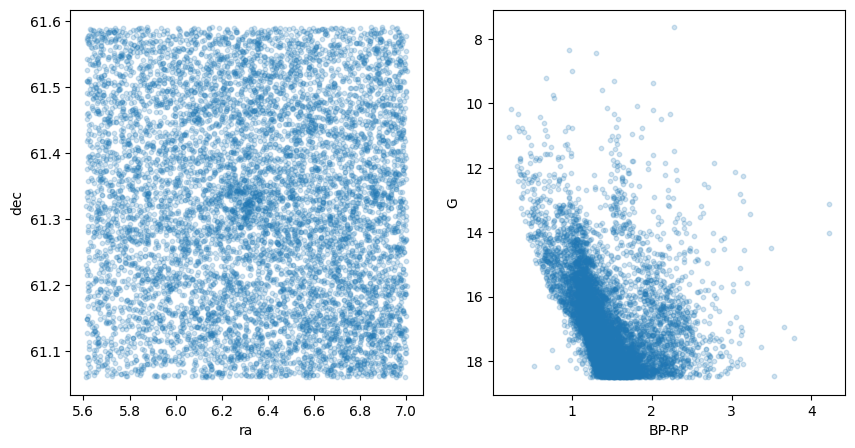

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Load data from field
field_df = pd.read_csv("../../_static/field.csv")

# Save for later plotting
field_color, field_mag = field_df['BP-RP'], field_df['Gmag']

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))
ax1.scatter(field_df['RA_ICRS'], field_df['DE_ICRS'], alpha=.2, s=10)
ax1.set_xlabel("ra")
ax1.set_ylabel("dec")
ax2.scatter(field_color, field_mag, alpha=.2, s=10)
ax2.invert_yaxis()
ax2.set_xlabel("BP-RP")
ax2.set_ylabel("G");

## fastMP method

We begin by loading the required packages and our field data file, and use this data to create an [Cluster](asteca.Cluster) object which we call `my_field`:

In [2]:
import asteca

my_field = asteca.Cluster(
    ra=field_df["RA_ICRS"],
    dec=field_df["DE_ICRS"],
    mag=field_df["Gmag"],
    color=field_df["BP-RP"],
    pmra=field_df["pmRA"],
    pmde=field_df["pmDE"],
    plx=field_df["Plx"],
    e_mag=field_df["e_Gmag"],
    e_color=field_df["e_BP-RP"],
    e_pmra=field_df["e_pmRA"],
    e_pmde=field_df["e_pmDE"],
    e_plx=field_df["e_Plx"],
    verbose = 2
)


Instantiating cluster from data
Columns read   : ra, dec, mag, e_mag, color, e_color, plx, e_plx, pmra, e_pmra, pmde, e_pmde
N_stars        : 8683
N_clust_min    : 25
N_clust_max    : 2000
Cluster object generated


Before running the `fastmp` method we need to estimate the center and approximated number of members for the cluster. The number of members in the cluster is a crucial parameter in the estimation of membership probabilities. **ASteCA** currently contains two methods within the [get_nmembers()](asteca.Cluster.get_nmembers) method, to perform this estimation. We use here the default methods both to estimate the center and the number of member stars.

In [3]:
# Estimate the cluster's center coordinates, use the default algorithm
my_field.get_center()

# Estimate the number of cluster members, use the default algorithm
my_field.get_nmembers()


Center coordinates found
radec_c        : (6.3049, 61.3218)
pms_c          : (-2.812, -1.070)
plx_c          : 0.288

Number of members estimated
N_cluster      : 285


With the required parameters loaded in the `my_field` object, we can call the `fastmp` method (defined in the [Membership](asteca.Membership) class) to obtain the membership probabilities for all the stars in the observed frame:

In [4]:
# Run fastMP on my_field
my_field.membership.fastmp()


Running fastMP
lonlat_c       : (119.7908, -1.3899)
pms_c          : (-2.812, -1.070)
plx_c          : 0.288
fixed_centers  : True
N_cluster      : 285
N_resample     : 1000
Convergence reached at 96 runs
Probabilities stored in 'probs' attribute


As stated in the output message, the probabilities are stored in the `probs` attribute of `my_field`.

To select the most likely members we use the [select_members()](asteca.Membership.select_members) method, where we can use different approaches to select stars with large membership probabilities. By default the method applies a 50% probability cut to select the most likely members:

In [5]:
cluster_fastmp = my_field.membership.select_members()


Members selected with probability > 0.5
New Cluster object created
N_cluster      : 297 (kept)
Field stars    : 8386 (removed)


Notice that the method selects the stars with probabilities larger than 50% and discards the rest. This method generates a new `Cluster` object which contains the most likely cluster members only.

Finally we plot the CMD of the field, coloring the stars according to their membership probabilities (only those with P>50%):

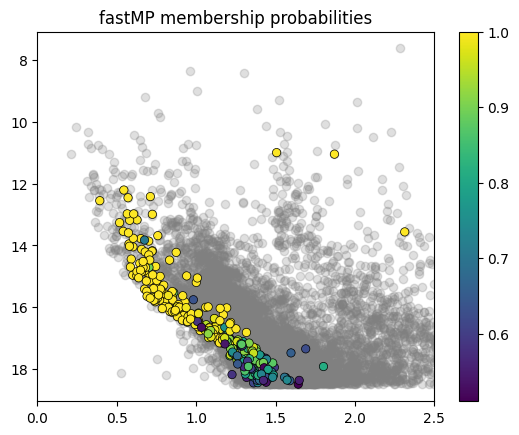

In [6]:
plt.title("fastMP membership probabilities")
plt.scatter(field_color, field_mag, c='grey', alpha=.25)
plt.scatter(cluster_fastmp.color, cluster_fastmp.mag, c=cluster_fastmp.probs, ec='k', lw=.5)
plt.gca().invert_yaxis()
plt.xlim(0, 2.5)
plt.colorbar();

## Bayesian method

As stated in the in the [Membership module](../membership_mod) section, the `bayesian` method should only be preferred over `fastmp` when there is no proper motions and parallax data available. In those cases, the `fastmp` method will most likely give better results.

We will show here how the `bayesian` method can be used with photometric data exclusively. We thus re-instantiate a `Cluster` object without proper motions and parallax data:

In [7]:
my_field = asteca.Cluster(
    ra=field_df["RA_ICRS"],
    dec=field_df["DE_ICRS"],
    mag=field_df["Gmag"],
    e_mag=field_df["e_Gmag"],
    color=field_df["BP-RP"],
    e_color=field_df["e_BP-RP"],
    verbose=2
)


Instantiating cluster from data
Columns read   : ra, dec, mag, e_mag, color, e_color
N_stars        : 8683
N_clust_min    : 25
N_clust_max    : 2000
Cluster object generated


Now we need to estimate the center coordinates and number of members (just like with `fastmp`) and in addition we need to add a `radius` argument (which is not required for `fastmp`).

We will use here the `density` algorithm of the `get_nmebers()` method to estimate the number of members, but we could have used the same default method used above with `fastmp` (or even set this argument manually):

In [8]:
# Estimate the cluster's center coordinates, using
# the `kde_2d` algorithm and (RA, DEC) data
my_field.get_center("kde_2d")

# Add a radius attribute manually
my_field.radius = 0.09  # in degrees

# Estimate the number of cluster members, using the `density` algorithm
my_field.get_nmembers("density")


Center coordinates found
radec_c        : (6.3142, 61.3262)

Number of members estimated
N_cluster      : 247


Now we can obtain the membership probabilities using the `bayesian` method:

In [9]:
# Run `bayesian` method
my_field.membership.bayesian()


Running Bayesian DA
radec_c        : (6.3142, 61.3262)
radius         : 0.0900 [deg]
N_cluster      : 247
N_runs         : 1000
Convergence reached at 87 runs
Probabilities stored in 'probs' attribute


Once again, we use the `Membership.select_members()` method to keep only those stars that are most likely to be cluster members in the `my_field` object:

In [10]:
cluster_bayesian = my_field.membership.select_members()


Members selected with probability > 0.5
New Cluster object created
N_cluster      : 428 (kept)
Field stars    : 8255 (removed)


and plot the final result:

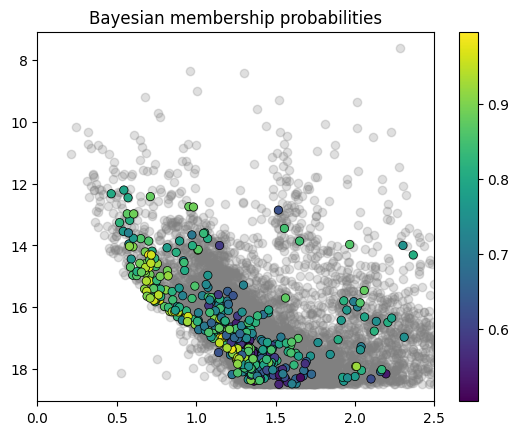

In [11]:
plt.title("Bayesian membership probabilities")
plt.scatter(field_color, field_mag, c='grey', alpha=.25)
plt.scatter(cluster_bayesian.color, cluster_bayesian.mag, c=cluster_bayesian.probs, ec='k', lw=.5)
plt.gca().invert_yaxis()
plt.xlim(0, 2.5)
plt.colorbar();

A side-by-side plot of the CMDs shows that the stars with P>50% selected by each of the methods are not necessarily the same, as is their assigned membership probabilities.

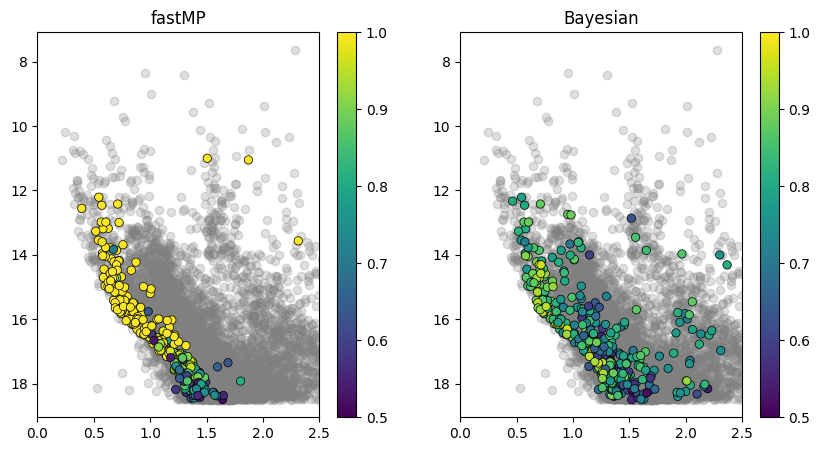

In [13]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

# fastMP membership
ax1.set_title("fastMP")
ax1.scatter(field_color, field_mag, c='grey', alpha=.25)
im1= ax1.scatter(cluster_fastmp.color, cluster_fastmp.mag, c=cluster_fastmp.probs, ec='k', lw=.5, vmin=0.5, vmax=1)
ax1.invert_yaxis()
ax1.set_xlim(0, 2.5)
fig.colorbar(im1, ax=ax1)

# Bayesian memberhsip
ax2.set_title("Bayesian")
ax2.scatter(field_color, field_mag, c='grey', alpha=.25)
im2 = ax2.scatter(cluster_bayesian.color, cluster_bayesian.mag, c=cluster_bayesian.probs, ec='k', lw=.5, vmin=0.5, vmax=1)
ax2.invert_yaxis()
ax2.set_xlim(0, 2.5)
fig.colorbar(im2, ax=ax2);